# Predicting Restaurant Partner Churn

## CA2 – Exploratory Data Analysis and Data Preparation

**Module:** Strategic Thinking

**Lecturer:** Taufique Ahmed

**Student:** Julia Evelin Gueno

## 1. Introduction

This project investigates restaurant partner churn
in food delivery platforms based on customer
service contact patterns.

The dataset contains 1,000 synthetic restaurant
records, including delivery issues, support issues,
payment issues and contact frequency.

The objective of this stage is to explore the data,
identify patterns, assess data quality and prepare
the dataset for future predictive modelling.

## 2. Data Understanding

The dataset used in this analysis was created during
CA1 and contains 1,000 synthetic restaurant records.

This section examines the dataset structure, variables,
data types and initial data quality.

As the dataset is synthetic, the results represent
simulated patterns rather than actual restaurant behaviour.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("restaurant_churn_synthetic.csv")

df.head()

,restaurants_id,delivery_issues,support_issues,payment_issues,contact_frequency,churn
0,1,4,4,0,9,1
1,2,1,1,0,3,0
2,3,3,1,2,8,0
3,4,3,1,1,6,0
4,5,1,1,0,4,0


### 2.1 Dataset Structure

The dataset structure is examined to identify the
number of observations, variables and data types.

This step helps to understand the dataset before
performing exploratory data analysis and data preparation.

In [3]:
# Check the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check data types and dataset information
df.info()

Number of rows: 1000
Number of columns: 6
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   restaurants_id     1000 non-null   int64
 1   delivery_issues    1000 non-null   int64
 2   support_issues     1000 non-null   int64
 3   payment_issues     1000 non-null   int64
 4   contact_frequency  1000 non-null   int64
 5   churn              1000 non-null   int64
dtypes: int64(6)
memory usage: 47.0 KB


**Interpretation:**

The dataset contains 1,000 observations and six
variables. All columns are stored as integers,
and no missing values were identified.

The restaurants_id column is an identifier, while
churn is the target variable, where 0 represents
retained restaurants and 1 represents restaurants
that left the platform.

The remaining four variables represent operational
issues and customer service contact frequency.

Although all columns are stored as integers,
they have different analytical purposes.
The restaurant identifier will not be used
as a predictive feature.

### 2.2 Variable Description (Data Dictionary)

The following table describes the variables used in
the dataset and their analytical roles.

| Variable | Description | Variable Type | Role |
|---|---|---|---|
| restaurants_id | Unique restaurant identifier | Identifier | Identification |
| delivery_issues | Number of delivery-related issues | Discrete numerical | Feature |
| support_issues | Number of customer support issues | Discrete numerical | Feature |
| payment_issues | Number of payment-related issues | Discrete numerical | Feature |
| contact_frequency | Total number of customer service contacts | Discrete numerical | Feature |
| churn | Restaurant retention status (0 = retained, 1 = left) | Binary categorical | Target |

The four operational variables will be explored to
identify potential relationships with restaurant churn.
The restaurant identifier will be excluded from
future predictive modelling.

### 2.3 Data Quality Assessment

Data quality is an important step in data preparation.

The dataset will be checked for missing values,
duplicate records and invalid values to ensure
consistency and reliability before further analysis.

In [4]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
restaurants_id       0
delivery_issues      0
support_issues       0
payment_issues       0
contact_frequency    0
churn                0
dtype: int64

Total missing values: 0


**Interpretation:**

No missing values were found in any of the six
variables. Therefore, data imputation and record
removal are not required to address missing data.

This result is consistent with the controlled
generation of the synthetic dataset. However,
the absence of missing values does not guarantee
overall data quality.

#### 2.3.2 Duplicate Records

Duplicate records and repeated restaurant identifiers
are checked to ensure that each restaurant is
represented only once in the dataset.

In [5]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate restaurant IDs
print("Duplicate restaurant IDs:",
      df["restaurants_id"].duplicated().sum())

Duplicate rows: 0
Duplicate restaurant IDs: 0


**Interpretation:**

No duplicate rows or repeated restaurant identifiers
were found in the dataset.

This confirms that each restaurant has a unique
identifier. Therefore, no records need to be removed
due to duplication.

#### 2.3.3 Invalid Values

The dataset is checked for negative values in
operational variables and invalid values in the
target variable.

Operational counts must be non-negative, while
the churn variable must contain only 0 or 1.

In [6]:
# Define operational variables
features = ["delivery_issues", "support_issues",
            "payment_issues", "contact_frequency"]

# Check negative values
print("Negative values per feature:")
print((df[features] < 0).sum())

# Check invalid target values
print("\nInvalid churn values:",
      (~df["churn"].isin([0, 1])).sum())

Negative values per feature:
delivery_issues      0
support_issues       0
payment_issues       0
contact_frequency    0
dtype: int64

Invalid churn values: 0


**Interpretation:**

No duplicate rows or repeated restaurant identifiers
were found in the dataset.

This confirms that each restaurant has a unique
identifier. Therefore, no records need to be removed
due to duplication.

#### 2.3.3 Invalid Values

The dataset is checked for negative values in
operational variables and invalid values in the
target variable.

Operational counts must be non-negative, while
the churn variable must contain only 0 or 1.

In [7]:
# Define operational variables
features = ["delivery_issues", "support_issues",
            "payment_issues", "contact_frequency"]

# Check negative values
print("Negative values per feature:")
print((df[features] < 0).sum())

# Check invalid target values
print("\nInvalid churn values:",
      (~df["churn"].isin([0, 1])).sum())

Negative values per feature:
delivery_issues      0
support_issues       0
payment_issues       0
contact_frequency    0
dtype: int64

Invalid churn values: 0


**Interpretation:**

No negative values were found in the operational
variables, and all churn values are either 0 or 1.

Therefore, no corrections are required based on
the validation rules applied.

#### 2.3.4 Data Consistency

A consistency check is performed to verify whether
contact frequency is equal to or greater than the
total number of operational issues.

This validation is based on the original rules
used to generate the synthetic dataset.

In [8]:
# Calculate total operational issues
total_issues = (
    df["delivery_issues"] +
    df["support_issues"] +
    df["payment_issues"]
)

# Check data consistency
inconsistent_records = (
    df["contact_frequency"] < total_issues
).sum()

print("Inconsistent records:", inconsistent_records)

Inconsistent records: 0


**Interpretation:**

No inconsistent records were identified. Contact
frequency is equal to or greater than the total
number of operational issues in all observations.

This confirms that the dataset follows the original
simulation rules. However, this relationship may
not represent real-world customer service behaviour.

#### 2.3.5 Data Quality Summary

| Quality Check | Result | Action Required |
|---|---|---|
| Missing values | 0 | No imputation |
| Duplicate rows | 0 | No removal |
| Duplicate restaurant IDs | 0 | No removal |
| Negative values | 0 | No correction |
| Invalid churn values | 0 | No correction |
| Inconsistent records | 0 | No correction |

Based on these checks, all 1,000 records can be
retained for further exploratory data analysis.

However, outlier detection and distribution analysis
are still required before completing data preparation.

In [7]:
n_restaurants = 1000
np.random.seed(42)

In [8]:
restaurants_id = np.arange(1,n_restaurants +1 )

In [9]:
delivery_issues = np.random.poisson (lam = 2,size=n_restaurants)

In [10]:
support_issues = np.random.poisson(lam=1.5, size= n_restaurants)

In [11]:
payment_issues= np.random.poisson(lam=0.8, size=n_restaurants)

In [16]:
contact_frequency=(delivery_issues + support_issues+payment_issues + np.random.poisson(lam=1, size= n_restaurants))

In [20]:
df = pd.DataFrame({"restaurants_id":restaurants_id,"delivery_issues":delivery_issues,"support_issues":support_issues,"payment_issues":payment_issues,"contact_frequency":contact_frequency})

In [22]:
df.head()

,restaurants_id,delivery_issues,support_issues,payment_issues,contact_frequency
0,1,4,4,0,9
1,2,1,1,0,3
2,3,3,1,2,8
3,4,3,1,1,6
4,5,1,1,0,4


In [23]:
churn_score=(-3+0.35*delivery_issues+0.45*support_issues+0.55*payment_issues+0.12*contact_frequency)

In [31]:
churn_probability = 1 / (1 + np.exp(-churn_score))

In [32]:
churn = np.random.binomial(1, churn_probability)

In [33]:
df["churn"] = churn

In [34]:
df.head(10)

,restaurants_id,delivery_issues,support_issues,payment_issues,contact_frequency,churn
0,1,4,4,0,9,1
1,2,1,1,0,3,0
2,3,3,1,2,8,0
3,4,3,1,1,6,0
4,5,1,1,0,4,0
5,6,2,2,3,7,1
6,7,1,2,1,4,1
7,8,1,2,1,5,0
8,9,2,3,1,7,0
9,10,2,1,0,4,0


In [35]:
df["churn"].value_counts()

churn
0    616
1    384
Name: count, dtype: int64

In [36]:
df["churn"].value_counts(normalize=True)

churn
0    0.616
1    0.384
Name: proportion, dtype: float64

In [39]:
df.to_csv("restaurant_churn_synthetic.csv",index = False)

In [40]:
df.describe()

,restaurants_id,delivery_issues,support_issues,payment_issues,contact_frequency,churn
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,2.003000,1.472000,0.826000,5.256000,0.384000
std,288.819436,1.416686,1.191905,0.885725,2.170063,0.486601
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,250.750000,1.000000,1.000000,0.000000,4.000000,0.000000
50%,500.500000,2.000000,1.000000,1.000000,5.000000,0.000000
75%,750.250000,3.000000,2.000000,1.000000,7.000000,1.000000
max,1000.000000,8.000000,6.000000,4.000000,14.000000,1.000000


In [42]:
df.groupby("churn")[["delivery_issues","support_issues","payment_issues","contact_frequency"]].mean()

,delivery_issues,support_issues,payment_issues,contact_frequency
churn,,,,
0,1.761364,1.172078,0.662338,4.521104
1,2.390625,1.953125,1.088542,6.434896


In [46]:
import matplotlib.pyplot as plt

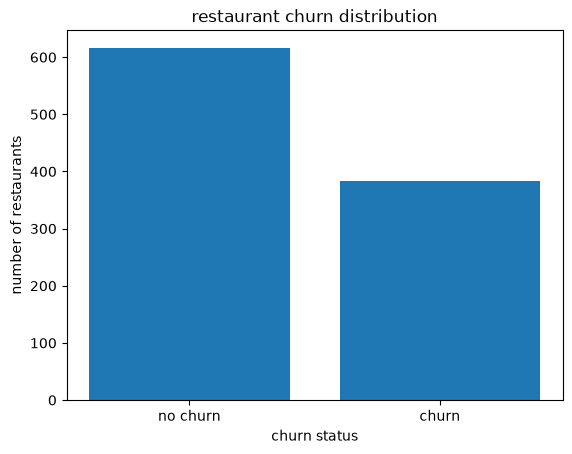

In [53]:
churn_counts=df["churn"].value_counts()
plt.bar(["no churn","churn"],[churn_counts[0],churn_counts[1]])
plt.xlabel("churn status")
plt.ylabel("number of restaurants")
plt.title("restaurant churn distribution")
plt.show()

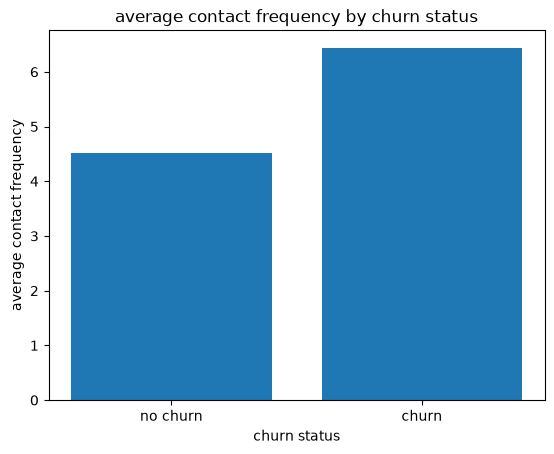

In [56]:
contact_mean=df.groupby("churn")["contact_frequency"].mean()
plt.bar(["no churn","churn"],contact_mean)
plt.xlabel("churn status")
plt.ylabel("average contact frequency")
plt.title("average contact frequency by churn status")
plt.show()

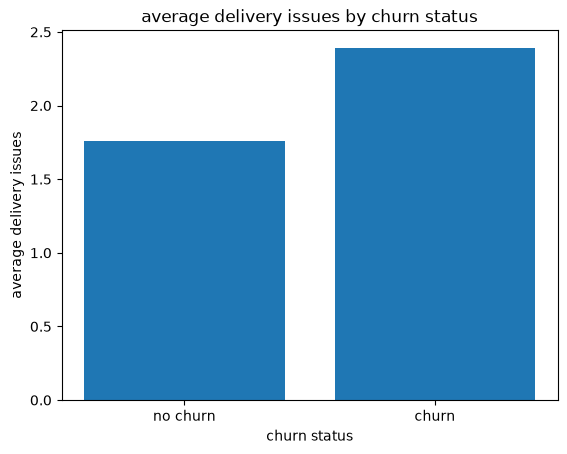

In [57]:
delivery_mean=df.groupby("churn")["delivery_issues"].mean()
plt.bar(["no churn","churn"],delivery_mean)
plt.xlabel("churn status")
plt.ylabel("average delivery issues")
plt.title("average delivery issues by churn status")
plt.show()

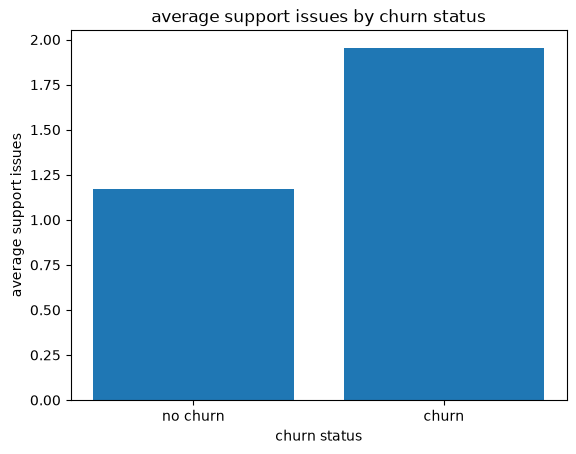

In [58]:
support_mean=df.groupby("churn")["support_issues"].mean()
plt.bar(["no churn","churn"],support_mean)
plt.xlabel("churn status")
plt.ylabel("average support issues")
plt.title("average support issues by churn status")
plt.show()


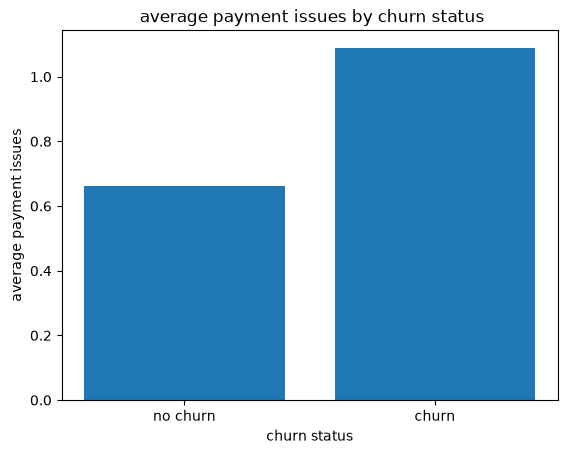

In [59]:
payment_mean= df.groupby("churn")["payment_issues"].mean()
plt.bar(["no churn","churn"],payment_mean)
plt.xlabel("churn status")
plt.ylabel("average payment issues")
plt.title(" average payment issues by churn status")
plt.show()

In [60]:
support_churn_rate=df.groupby("support_issues")["churn"].mean()
support_churn_rate

support_issues
0    0.216814
1    0.294643
2    0.456349
3    0.606061
4    0.717949
5    0.900000
6    0.800000
Name: churn, dtype: float64

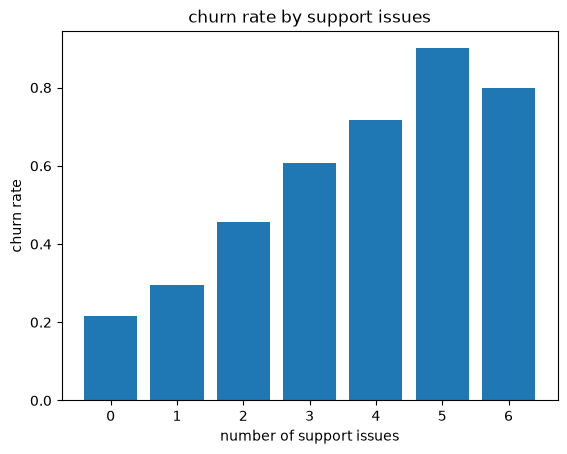

In [61]:
plt.bar(support_churn_rate.index, support_churn_rate.values)
plt.xlabel("number of support issues")
plt.ylabel("churn rate")
plt.title("churn rate by support issues")
plt.show()

In [63]:
payment_churn_rate= df.groupby("payment_issues")["churn"].mean()
payment_churn_rate

payment_issues
0    0.283063
1    0.392954
2    0.557047
3    0.644444
4    0.833333
Name: churn, dtype: float64

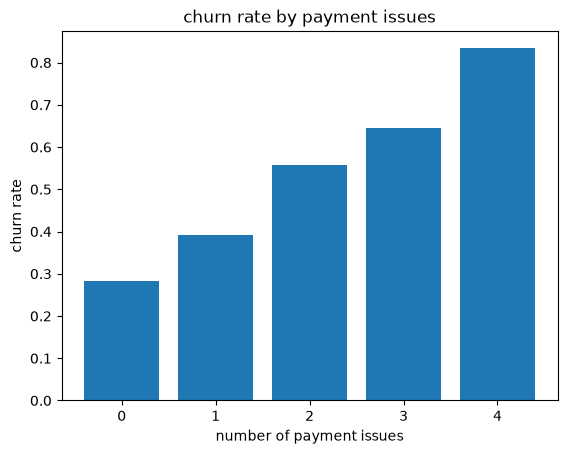

In [64]:
plt.bar(payment_churn_rate.index, payment_churn_rate.values)
plt.xlabel("number of payment issues")
plt.ylabel("churn rate")
plt.title("churn rate by payment issues")
plt.show()

In [65]:
delivery_churn_rate=df.groupby("delivery_issues")["churn"].mean()
delivery_churn_rate

delivery_issues
0    0.283688
1    0.296154
2    0.351449
3    0.471591
4    0.561798
5    0.613636
6    0.666667
7    1.000000
8    1.000000
Name: churn, dtype: float64

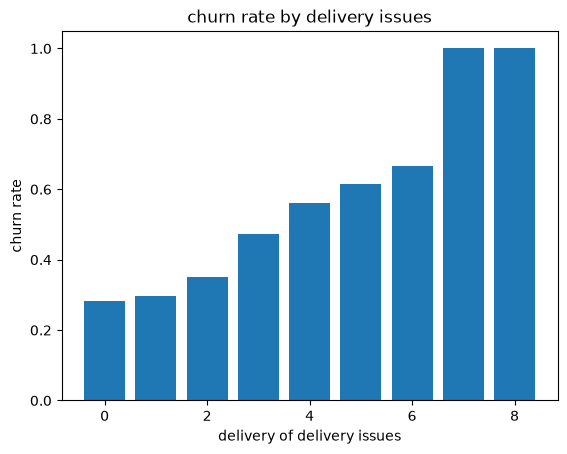

In [67]:
plt.bar(delivery_churn_rate.index, delivery_churn_rate.values)
plt.xlabel("delivery of delivery issues")
plt.ylabel("churn rate")
plt.title("churn rate by delivery issues")
plt.show()

In [71]:
from sklearn.model_selection import train_test_split



In [76]:
X = df[["delivery_issues", "support_issues", "payment_issues", "contact_frequency"]]

y = df["churn"]

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [78]:
print(X_train.shape)
print(X_test.shape)

(800, 4)
(200, 4)


In [83]:
from sklearn.ensemble import RandomForestClassifier

In [87]:
model = RandomForestClassifier(n_estimators=100,random_state=42)

In [92]:
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [97]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 1 1 0 0 0 0 0 0 1]


In [100]:
print(y_test[:10].values)

[1 1 0 0 0 0 1 1 0 1]


In [101]:
from sklearn.metrics import accuracy_score

In [102]:
accuracy=accuracy_score(y_test,y_pred)

In [103]:
print(accuracy)

0.695


In [105]:
from sklearn.metrics import confusion_matrix

In [107]:
cm = confusion_matrix(y_test, y_pred)

In [108]:
print(cm)

[[101  27]
 [ 34  38]]


In [109]:
from sklearn.metrics import precision_score

In [112]:
precision = precision_score(y_test, y_pred)

In [113]:
print(precision)

0.5846153846153846


In [114]:
from sklearn.metrics import f1_score

In [116]:
f1 = f1_score(y_test, y_pred)

In [117]:
print(f1)

0.5547445255474452


In [118]:
model.feature_importances_

array([0.23063057, 0.2177881 , 0.16324337, 0.38833796])

In [123]:
importance = pd.Series(model.feature_importances_, index = X.columns)
print(importance)

delivery_issues      0.230631
support_issues       0.217788
payment_issues       0.163243
contact_frequency    0.388338
dtype: float64
